In [ ]:
!nvidia-smi

Fri Sep 18 06:23:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Install the ESA OpenSR packages

For our first prototype, use the lightweight SEN2SR model rather than the full Mamba/diffusion model.

In [ ]:
!pip install -q sen2sr mlstac git+https://github.com/ESDS-Leipzig/cubo.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 11.7 MB/s eta 0:00:00


This follows the current SEN2SR installation path

then run below

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU not available")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


Download the pretrained model

We're going to use:

    SEN2SRLite NonReference_RGBN_x4

Why this one?

Because it directly accepts:

    B04 = Red

    B03 = Green

    B02 = Blue

    B08 = NIR

at 10 m and produces a ×4 SR product.

ESA provides this pretrained model and example workflow

In [ ]:
import mlstac

mlstac.download(
    file="https://huggingface.co/tacofoundation/sen2sr/resolve/main/SEN2SRLite/NonReference_RGBN_x4/mlm.json",
    output_dir="model/SEN2SRLite_RGBN"
)

print("Model downloaded.")

Model downloaded.


Step 4 — Load the model

In [ ]:
import torch
import mlstac

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = mlstac.load(
    "model/SEN2SRLite_RGBN"
).compiled_model(device=device)

model = model.to(device)
model.eval()

print("Model loaded successfully.")
print("Device:", device)

Model loaded successfully.
Device: cuda


At this point we have:

          ┌─────────────────────┐
          │ SEN2SRLite RGBN ×4  │
          └──────────┬──────────┘
                     │
               PRETRAINED
                     │
                     ▼
             Ready for inference

For the first test, use ESA's example data
Before downloading a huge Sentinel-2 scene, let's make sure inference works.

We'll first test the model with a small tensor.

In [ ]:
import torch

# Fake 10 m RGB+NIR test patch
X = torch.rand(
    1, 4, 128, 128,
    device=device
)

print("Input shape:", X.shape)

with torch.no_grad():
    SR = model(X)

print("Output shape:", SR.shape)

Input shape: torch.Size([1, 4, 128, 128])
Output shape: torch.Size([1, 4, 512, 512])


## 4. Download Sentinel-2 Data

We now test the pretrained SEN2SRLite model on real Sentinel-2 imagery.

Input:
- Sentinel-2 L2A
- 10 m spatial resolution
- B02, B03, B04, B08

Output:
- 2.5 m AI super-resolved product
- RGB + NIR

Install/import cubo

In [ ]:
import cubo
import torch
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
da = cubo.create(
    lat=39.49152740347753,
    lon=-0.4308725142800361,

    collection="sentinel-2-l2a",

    bands=["B04", "B03", "B02", "B08"],

    start_date="2023-01-01",
    end_date="2023-12-31",

    edge_size=128,
    resolution=10
)

print(da)

<xarray.DataArray 'sentinel-2-l2a' (time: 251, band: 4, y: 128, x: 128)> Size: 132MB
dask.array<fetch_raster_window, shape=(251, 4, 128, 128), dtype=float64, chunksize=(1, 1, 128, 128), chunktype=numpy.ndarray>
Coordinates: (12/45)
  * time                                     (time) datetime64[ns] 2kB 2023-0...
  * band                                     (band) <U3 48B 'B04' ... 'B08'
  * y                                        (y) float64 1kB 4.375e+06 ... 4....
  * x                                        (x) float64 1kB 7.203e+05 ... 7....
    id                                       (time) <U54 54kB 'S2A_MSIL2A_202...
    s2:datatake_id                           (time) <U34 34kB 'GS2A_20230105T...
    ...                                       ...
    gsd                                      float64 8B 10.0
    common_name                              (band) <U5 80B 'red' ... 'nir'
    center_wavelength                        (band) float64 32B 0.665 ... 0.842
    full_width_half_

Check the downloaded data

In [ ]:
print("Dimensions:", da.dims)
print("Shape:", da.shape)
print("Coordinates:", list(da.coords))

Dimensions: ('time', 'band', 'y', 'x')
Shape: (251, 4, 128, 128)
Coordinates: ['time', 'id', 'band', 'x', 'y', 's2:datatake_id', 'instruments', 's2:product_uri', 's2:processing_baseline', 's2:granule_id', 's2:cloud_shadow_percentage', 's2:mgrs_tile', 'sat:relative_orbit', 's2:vegetation_percentage', 's2:datatake_type', 's2:generation_time', 's2:dark_features_percentage', 's2:product_type', 's2:mean_solar_zenith', 's2:nodata_pixel_percentage', 's2:saturated_defective_pixel_percentage', 's2:datastrip_id', 'proj:code', 's2:water_percentage', 'platform', 's2:high_proba_clouds_percentage', 's2:medium_proba_clouds_percentage', 'eo:cloud_cover', 's2:degraded_msi_data_percentage', 's2:not_vegetated_percentage', 'constellation', 's2:unclassified_percentage', 'sat:orbit_state', 's2:reflectance_conversion_factor', 's2:thin_cirrus_percentage', 's2:snow_ice_percentage', 's2:mean_solar_azimuth', 'proj:shape', 'title', 'gsd', 'common_name', 'center_wavelength', 'full_width_half_max', 'epsg', 'cubo:di

In [ ]:
print("Data type:", da.dtype)

Data type: float64


Extract the four bands

In [ ]:
print(da)

<xarray.DataArray 'sentinel-2-l2a' (time: 251, band: 4, y: 128, x: 128)> Size: 132MB
dask.array<fetch_raster_window, shape=(251, 4, 128, 128), dtype=float64, chunksize=(1, 1, 128, 128), chunktype=numpy.ndarray>
Coordinates: (12/45)
  * time                                     (time) datetime64[ns] 2kB 2023-0...
  * band                                     (band) <U3 48B 'B04' ... 'B08'
  * y                                        (y) float64 1kB 4.375e+06 ... 4....
  * x                                        (x) float64 1kB 7.203e+05 ... 7....
    id                                       (time) <U54 54kB 'S2A_MSIL2A_202...
    s2:datatake_id                           (time) <U34 34kB 'GS2A_20230105T...
    ...                                       ...
    gsd                                      float64 8B 10.0
    common_name                              (band) <U5 80B 'red' ... 'nir'
    center_wavelength                        (band) float64 32B 0.665 ... 0.842
    full_width_half_

Let's see which dates we downloaded

In [ ]:
print("Number of images:", len(da.time))

print("\nAvailable dates:")
for i, t in enumerate(da.time.values):
    print(i, t)

Number of images: 251

Available dates:
0 2023-01-05T10:54:31.024000000
1 2023-01-05T10:54:31.024000000
2 2023-01-10T10:53:29.024000000
3 2023-01-10T10:53:29.024000000
4 2023-01-10T10:53:29.024000000
5 2023-01-15T10:54:11.024000000
6 2023-01-15T10:54:11.024000000
7 2023-01-15T10:54:11.024000000
8 2023-01-20T10:52:49.024000000
9 2023-01-20T10:52:49.024000000
10 2023-01-25T10:53:31.024000000
11 2023-01-25T10:53:31.024000000
12 2023-01-30T10:52:09.024000000
13 2023-01-30T10:52:09.024000000
14 2023-01-30T10:52:09.024000000
15 2023-02-04T10:52:41.024000000
16 2023-02-04T10:52:41.024000000
17 2023-02-04T10:52:41.024000000
18 2023-02-04T10:52:41.024000000
19 2023-02-09T10:51:09.024000000
20 2023-02-09T10:51:09.024000000
21 2023-02-09T10:51:09.024000000
22 2023-02-09T10:51:09.024000000
23 2023-02-14T10:51:41.024000000
24 2023-02-14T10:51:41.024000000
25 2023-02-14T10:51:41.024000000
26 2023-02-14T10:51:41.024000000
27 2023-02-19T10:50:09.024000000
28 2023-02-19T10:50:09.024000000
29 2023-02-24

Select ONE Sentinel-2 image

For now, use the first available observation:

In [ ]:
sample_index = 0

sample = da.isel(time=sample_index)

print(sample)

<xarray.DataArray 'sentinel-2-l2a' (band: 4, y: 128, x: 128)> Size: 524kB
dask.array<getitem, shape=(4, 128, 128), dtype=float64, chunksize=(1, 128, 128), chunktype=numpy.ndarray>
Coordinates: (12/45)
  * band                                     (band) <U3 48B 'B04' ... 'B08'
  * y                                        (y) float64 1kB 4.375e+06 ... 4....
  * x                                        (x) float64 1kB 7.203e+05 ... 7....
    time                                     datetime64[ns] 8B 2023-01-05T10:...
    id                                       <U54 216B 'S2A_MSIL2A_20230105T1...
    s2:datatake_id                           <U34 136B 'GS2A_20230105T105431_...
    ...                                       ...
    gsd                                      float64 8B 10.0
    common_name                              (band) <U5 80B 'red' ... 'nir'
    center_wavelength                        (band) float64 32B 0.665 ... 0.842
    full_width_half_max                      (band)

Now actually download that one image

Why / 10_000?

Sentinel-2 L2A reflectance values are commonly stored as scaled integer values, and the current ESA SEN2SR example normalizes the selected Sentinel-2 sample by 10_000 before passing it into the mode

In [ ]:
original_s2_numpy = (
    sample.compute().to_numpy() / 10_000
).astype("float32")

print("Shape:", original_s2_numpy.shape)
print("Min:", np.nanmin(original_s2_numpy))
print("Max:", np.nanmax(original_s2_numpy))

Shape: (4, 128, 128)
Min: 0.0872
Max: 0.9016


Let's visualize the REAL Sentinel-2 image

Before doing AI super-resolution, we need to see the original image.

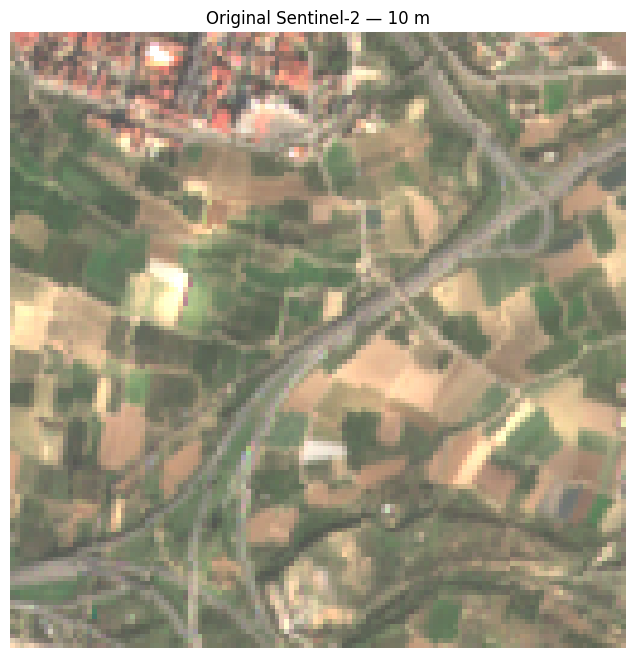

In [ ]:
rgb = np.transpose(
    original_s2_numpy[:3],
    (1, 2, 0)
)

# Improve display contrast
rgb_display = np.clip(rgb * 3, 0, 1)

plt.figure(figsize=(8, 8))
plt.imshow(rgb_display)
plt.title("Original Sentinel-2 — 10 m")
plt.axis("off")
plt.show()

Now we run the AI

In [ ]:
X = torch.from_numpy(
    original_s2_numpy
).float().to(device)

X = torch.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Model input:", X.shape)

with torch.no_grad():
    superX = model(X[None])

print("SR output:", superX.shape)

Model input: torch.Size([4, 128, 128])
SR output: torch.Size([1, 4, 512, 512])


Visualize 10 m vs AI Super-Resolved 2.5 m

Now we need to see whether the AI actually produces a useful improvement.

SR array shape: (4, 512, 512)


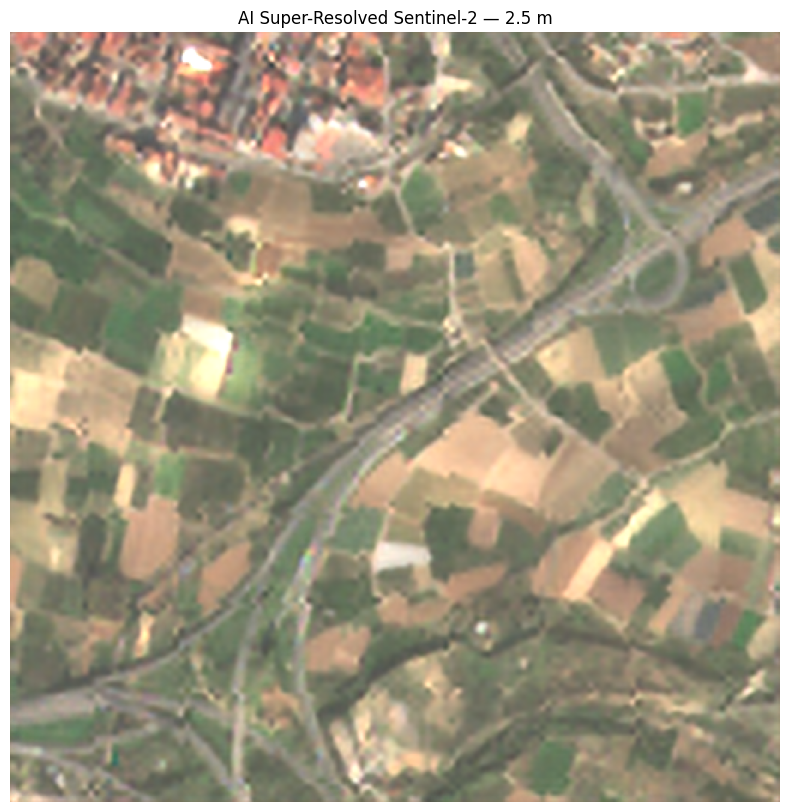

In [ ]:
# Remove batch dimension
superX_numpy = superX[0].detach().cpu().numpy()

print("SR array shape:", superX_numpy.shape)

# Convert RGB channels from CHW -> HWC
sr_rgb = np.transpose(
    superX_numpy[:3],
    (1, 2, 0)
)

# Display enhancement
sr_rgb_display = np.clip(sr_rgb * 3, 0, 1)

plt.figure(figsize=(10, 10))
plt.imshow(sr_rgb_display)
plt.title("AI Super-Resolved Sentinel-2 — 2.5 m")
plt.axis("off")
plt.show()

Side-by-side comparison

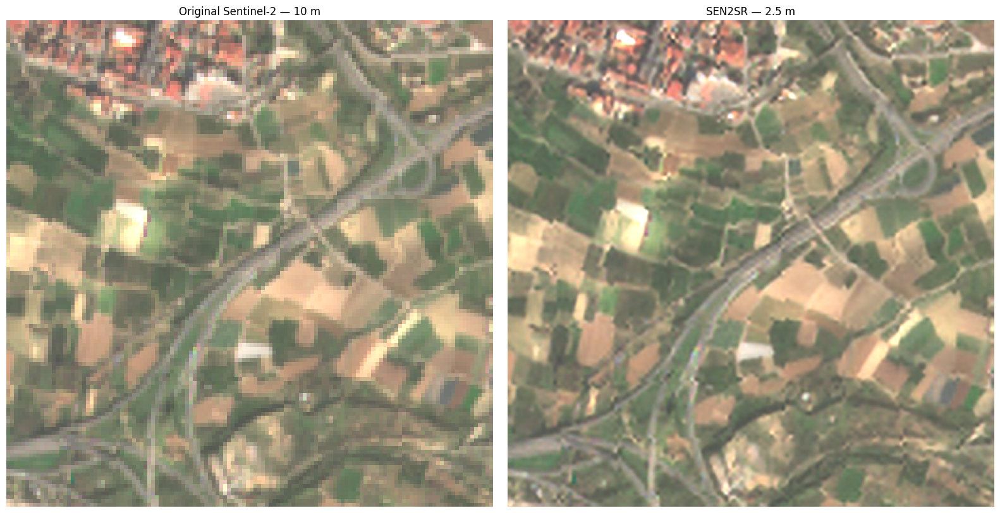

In [ ]:
# Create side-by-side comparison

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Original Sentinel-2 RGB
axes[0].imshow(rgb_display)
axes[0].set_title("Original Sentinel-2 — 10 m")
axes[0].axis("off")

# Super-resolved RGB
axes[1].imshow(sr_rgb_display)
axes[1].set_title("SEN2SR — 2.5 m")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Now we move to an important SIH-grade part: Spectral Consistency Validation.

The idea is simple:

    If the AI increases spatial resolution, it should not drastically change the scientific information in the image.

For Sentinel-2, we'll use NDVI as our first test.

$$ NDVI=\frac{NIR-Red}{NIR+Red} $$

Your bands are:

    B04 → Red
    B08 → NIR

Calculate NDVI before and after SR

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize

# --------------------------------------------------
# 1. ORIGINAL SENTINEL-2 NDVI (10 m)
# --------------------------------------------------

red_original = original_s2_numpy[0]
nir_original = original_s2_numpy[3]

ndvi_original = (
    (nir_original - red_original) /
    (nir_original + red_original + 1e-8)
)

# --------------------------------------------------
# 2. SUPER-RESOLVED NDVI (2.5 m)
# --------------------------------------------------

red_sr = superX_numpy[0]
nir_sr = superX_numpy[3]

ndvi_sr = (
    (nir_sr - red_sr) /
    (nir_sr + red_sr + 1e-8)
)

# Remove unrealistic values
ndvi_original = np.clip(ndvi_original, -1, 1)
ndvi_sr = np.clip(ndvi_sr, -1, 1)

# --------------------------------------------------
# 3. Resize SR NDVI to 10 m grid
# --------------------------------------------------
# This makes a fair pixel-to-pixel comparison.

ndvi_sr_10m = resize(
    ndvi_sr,
    ndvi_original.shape,
    order=1,
    preserve_range=True,
    anti_aliasing=True
)

# --------------------------------------------------
# 4. Calculate difference
# --------------------------------------------------

ndvi_difference = np.abs(
    ndvi_original - ndvi_sr_10m
)

mae = np.mean(ndvi_difference)
rmse = np.sqrt(np.mean(
    (ndvi_original - ndvi_sr_10m) ** 2
))

print("Original NDVI shape:", ndvi_original.shape)
print("SR NDVI shape:", ndvi_sr.shape)
print("Comparison NDVI shape:", ndvi_sr_10m.shape)

print("\nNDVI Mean Absolute Error (MAE):", mae)
print("NDVI RMSE:", rmse)

Original NDVI shape: (128, 128)
SR NDVI shape: (512, 512)
Comparison NDVI shape: (128, 128)

NDVI Mean Absolute Error (MAE): 0.0065087476
NDVI RMSE: 0.008501168


This lets us calculate:
MAE

Mean Absolute Error

Lower means the SR-derived NDVI is closer to the original NDVI.

RMSE

Root Mean Square Error

This gives more weight to larger differences.

###Visualize the NDVI comparison

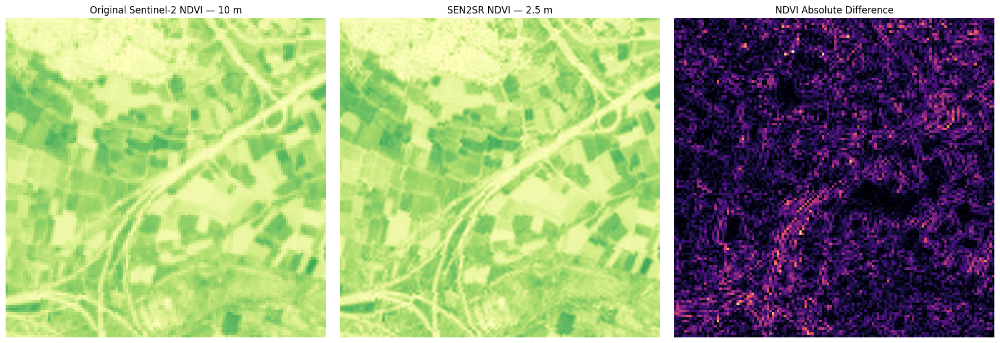

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Original NDVI
im1 = axes[0].imshow(
    ndvi_original,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
axes[0].set_title("Original Sentinel-2 NDVI — 10 m")
axes[0].axis("off")

# SR NDVI
im2 = axes[1].imshow(
    ndvi_sr,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
axes[1].set_title("SEN2SR NDVI — 2.5 m")
axes[1].axis("off")

# Difference
im3 = axes[2].imshow(
    ndvi_difference,
    cmap="magma"
)
axes[2].set_title("NDVI Absolute Difference")
axes[2].axis("off")

plt.tight_layout()
plt.show()

##Large-area Super Resolution

We'll first test this on a 512×512 Sentinel-2 input
###Create a larger Sentinel-2 cube

In [ ]:
import cubo
import torch
import numpy as np

large_da = cubo.create(
    lat=39.49152740347753,
    lon=-0.4308725142800361,
    collection="sentinel-2-l2a",
    bands=["B04", "B03", "B02", "B08"],
    start_date="2023-01-01",
    end_date="2023-12-31",
    edge_size=512,
    resolution=10
)

print(large_da)

<xarray.DataArray 'sentinel-2-l2a' (time: 251, band: 4, y: 512, x: 512)> Size: 2GB
dask.array<fetch_raster_window, shape=(251, 4, 512, 512), dtype=float64, chunksize=(1, 1, 512, 512), chunktype=numpy.ndarray>
Coordinates: (12/45)
  * time                                     (time) datetime64[ns] 2kB 2023-0...
  * band                                     (band) <U3 48B 'B04' ... 'B08'
  * y                                        (y) float64 4kB 4.377e+06 ... 4....
  * x                                        (x) float64 4kB 7.184e+05 ... 7....
    id                                       (time) <U54 54kB 'S2A_MSIL2A_202...
    s2:datatake_id                           (time) <U34 34kB 'GS2A_20230105T...
    ...                                       ...
    gsd                                      float64 8B 10.0
    common_name                              (band) <U5 80B 'red' ... 'nir'
    center_wavelength                        (band) float64 32B 0.665 ... 0.842
    full_width_half_ma

We want to choose one observation, just as we did previously.

In [ ]:
print("Number of images:", len(large_da.time))

for i, t in enumerate(large_da.time.values):
    print(i, t)

Number of images: 251
0 2023-01-05T10:54:31.024000000
1 2023-01-05T10:54:31.024000000
2 2023-01-10T10:53:29.024000000
3 2023-01-10T10:53:29.024000000
4 2023-01-10T10:53:29.024000000
5 2023-01-15T10:54:11.024000000
6 2023-01-15T10:54:11.024000000
7 2023-01-15T10:54:11.024000000
8 2023-01-20T10:52:49.024000000
9 2023-01-20T10:52:49.024000000
10 2023-01-25T10:53:31.024000000
11 2023-01-25T10:53:31.024000000
12 2023-01-30T10:52:09.024000000
13 2023-01-30T10:52:09.024000000
14 2023-01-30T10:52:09.024000000
15 2023-02-04T10:52:41.024000000
16 2023-02-04T10:52:41.024000000
17 2023-02-04T10:52:41.024000000
18 2023-02-04T10:52:41.024000000
19 2023-02-09T10:51:09.024000000
20 2023-02-09T10:51:09.024000000
21 2023-02-09T10:51:09.024000000
22 2023-02-09T10:51:09.024000000
23 2023-02-14T10:51:41.024000000
24 2023-02-14T10:51:41.024000000
25 2023-02-14T10:51:41.024000000
26 2023-02-14T10:51:41.024000000
27 2023-02-19T10:50:09.024000000
28 2023-02-19T10:50:09.024000000
29 2023-02-24T10:50:31.02400000

In [ ]:
sample_index = 0

large_sample = large_da.isel(time=sample_index)

print(large_sample)

<xarray.DataArray 'sentinel-2-l2a' (band: 4, y: 512, x: 512)> Size: 8MB
dask.array<getitem, shape=(4, 512, 512), dtype=float64, chunksize=(1, 512, 512), chunktype=numpy.ndarray>
Coordinates: (12/45)
  * band                                     (band) <U3 48B 'B04' ... 'B08'
  * y                                        (y) float64 4kB 4.377e+06 ... 4....
  * x                                        (x) float64 4kB 7.184e+05 ... 7....
    time                                     datetime64[ns] 8B 2023-01-05T10:...
    id                                       <U54 216B 'S2A_MSIL2A_20230105T1...
    s2:datatake_id                           <U34 136B 'GS2A_20230105T105431_...
    ...                                       ...
    gsd                                      float64 8B 10.0
    common_name                              (band) <U5 80B 'red' ... 'nir'
    center_wavelength                        (band) float64 32B 0.665 ... 0.842
    full_width_half_max                      (band) f

Download only that scene

In [ ]:
large_s2_numpy = (
    large_sample.compute().to_numpy() / 10_000
).astype("float32")

large_s2_numpy = np.nan_to_num(
    large_s2_numpy,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Large input shape:", large_s2_numpy.shape)
print("Minimum:", large_s2_numpy.min())
print("Maximum:", large_s2_numpy.max())

Large input shape: (4, 512, 512)
Minimum: 0.0674
Maximum: 1.3608


### Run tiled AI inference

In [ ]:
import sen2sr

large_X = torch.from_numpy(
    large_s2_numpy
).float().to(device)

print("Input:", large_X.shape)

with torch.no_grad():
    large_superX = sen2sr.predict_large(
        model=model,
        X=large_X,
        overlap=32
    )

print("SR output:", large_superX.shape)

Input: torch.Size([4, 512, 512])


100%|██████████| 36/36 [00:00<00:00, 48.75it/s]

SR output: torch.Size([4, 2048, 2048])


So:

512 × 512 at 10 m

becomes

2048 × 2048 at 2.5 m.

That's a 16× increase in pixel count, while the physical area remains the same.

Instead of processing completely independent tiles, neighboring tiles overlap. This helps the reconstruction remain continuous at tile boundaries. ESA's current example uses the same predict_large(... overlap=32) approach.

###Choose one Sentinel-2 scene and download it

In [ ]:
print("Number of available images:", len(large_da.time))

print("\nAvailable acquisition dates:")
for i, t in enumerate(large_da.time.values):
    print(i, t)

Number of available images: 251

Available acquisition dates:
0 2023-01-05T10:54:31.024000000
1 2023-01-05T10:54:31.024000000
2 2023-01-10T10:53:29.024000000
3 2023-01-10T10:53:29.024000000
4 2023-01-10T10:53:29.024000000
5 2023-01-15T10:54:11.024000000
6 2023-01-15T10:54:11.024000000
7 2023-01-15T10:54:11.024000000
8 2023-01-20T10:52:49.024000000
9 2023-01-20T10:52:49.024000000
10 2023-01-25T10:53:31.024000000
11 2023-01-25T10:53:31.024000000
12 2023-01-30T10:52:09.024000000
13 2023-01-30T10:52:09.024000000
14 2023-01-30T10:52:09.024000000
15 2023-02-04T10:52:41.024000000
16 2023-02-04T10:52:41.024000000
17 2023-02-04T10:52:41.024000000
18 2023-02-04T10:52:41.024000000
19 2023-02-09T10:51:09.024000000
20 2023-02-09T10:51:09.024000000
21 2023-02-09T10:51:09.024000000
22 2023-02-09T10:51:09.024000000
23 2023-02-14T10:51:41.024000000
24 2023-02-14T10:51:41.024000000
25 2023-02-14T10:51:41.024000000
26 2023-02-14T10:51:41.024000000
27 2023-02-19T10:50:09.024000000
28 2023-02-19T10:50:09.0

In [ ]:
# Select the first available Sentinel-2 observation
sample_index = 0

large_sample = large_da.isel(time=sample_index)

print("Selected scene:")
print(large_sample)

Selected scene:
<xarray.DataArray 'sentinel-2-l2a' (band: 4, y: 512, x: 512)> Size: 8MB
dask.array<getitem, shape=(4, 512, 512), dtype=float64, chunksize=(1, 512, 512), chunktype=numpy.ndarray>
Coordinates: (12/45)
  * band                                     (band) <U3 48B 'B04' ... 'B08'
  * y                                        (y) float64 4kB 4.377e+06 ... 4....
  * x                                        (x) float64 4kB 7.184e+05 ... 7....
    time                                     datetime64[ns] 8B 2023-01-05T10:...
    id                                       <U54 216B 'S2A_MSIL2A_20230105T1...
    s2:datatake_id                           <U34 136B 'GS2A_20230105T105431_...
    ...                                       ...
    gsd                                      float64 8B 10.0
    common_name                              (band) <U5 80B 'red' ... 'nir'
    center_wavelength                        (band) float64 32B 0.665 ... 0.842
    full_width_half_max              

In [ ]:
# Download only the selected scene
large_s2_numpy = (
    large_sample.compute().to_numpy() / 10_000
).astype("float32")

# Remove invalid values
large_s2_numpy = np.nan_to_num(
    large_s2_numpy,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Large input shape:", large_s2_numpy.shape)
print("Minimum:", large_s2_numpy.min())
print("Maximum:", large_s2_numpy.max())

Large input shape: (4, 512, 512)
Minimum: 0.0674
Maximum: 1.3608


####Run large-area SEN2SR

In [ ]:
# Convert to PyTorch tensor
large_X = torch.from_numpy(
    large_s2_numpy
).float().to(device)

print("Model input:", large_X.shape)

# Large-area tiled inference
with torch.no_grad():
    large_superX = sen2sr.predict_large(
        model=model,
        X=large_X,
        overlap=32
    )

print("Super-resolved output:", large_superX.shape)

Model input: torch.Size([4, 512, 512])


100%|██████████| 36/36 [00:01<00:00, 35.28it/s]

Super-resolved output: torch.Size([4, 2048, 2048])


we did:

    large satellite scene → tiled AI processing → seamless high-resolution product

###Check the Large SR Image

Before exporting anything, let's visually inspect the full super-resolved scene.

SR NumPy shape: (4, 2048, 2048)


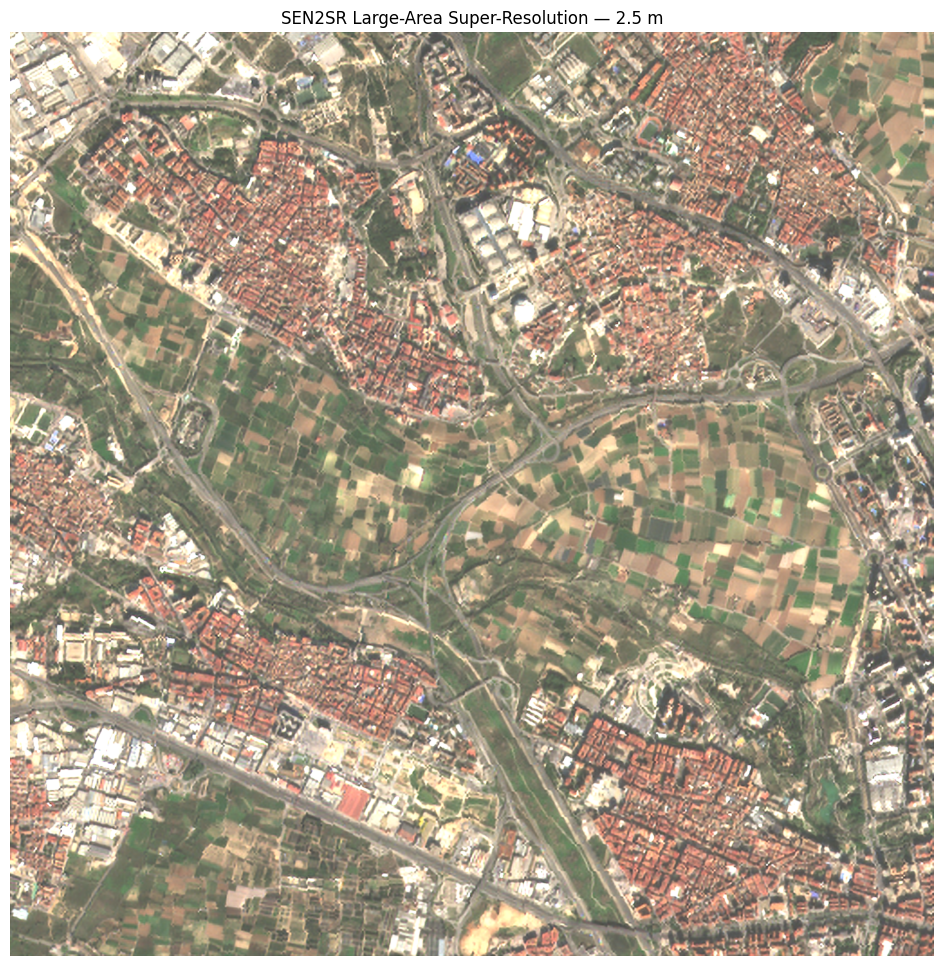

In [ ]:
# Convert SR tensor to NumPy
large_sr_numpy = large_superX.detach().cpu().numpy()

print("SR NumPy shape:", large_sr_numpy.shape)

# RGB: B04, B03, B02
large_sr_rgb = np.transpose(
    large_sr_numpy[:3],
    (1, 2, 0)
)

# Improve visualization
large_sr_display = np.clip(
    large_sr_rgb * 3,
    0,
    1
)

plt.figure(figsize=(12, 12))
plt.imshow(large_sr_display)
plt.title("SEN2SR Large-Area Super-Resolution — 2.5 m")
plt.axis("off")
plt.show()

###Check for tile boundaries

This is important because we're using tiled inference.

Let's zoom into the image and inspect whether obvious seams appear.

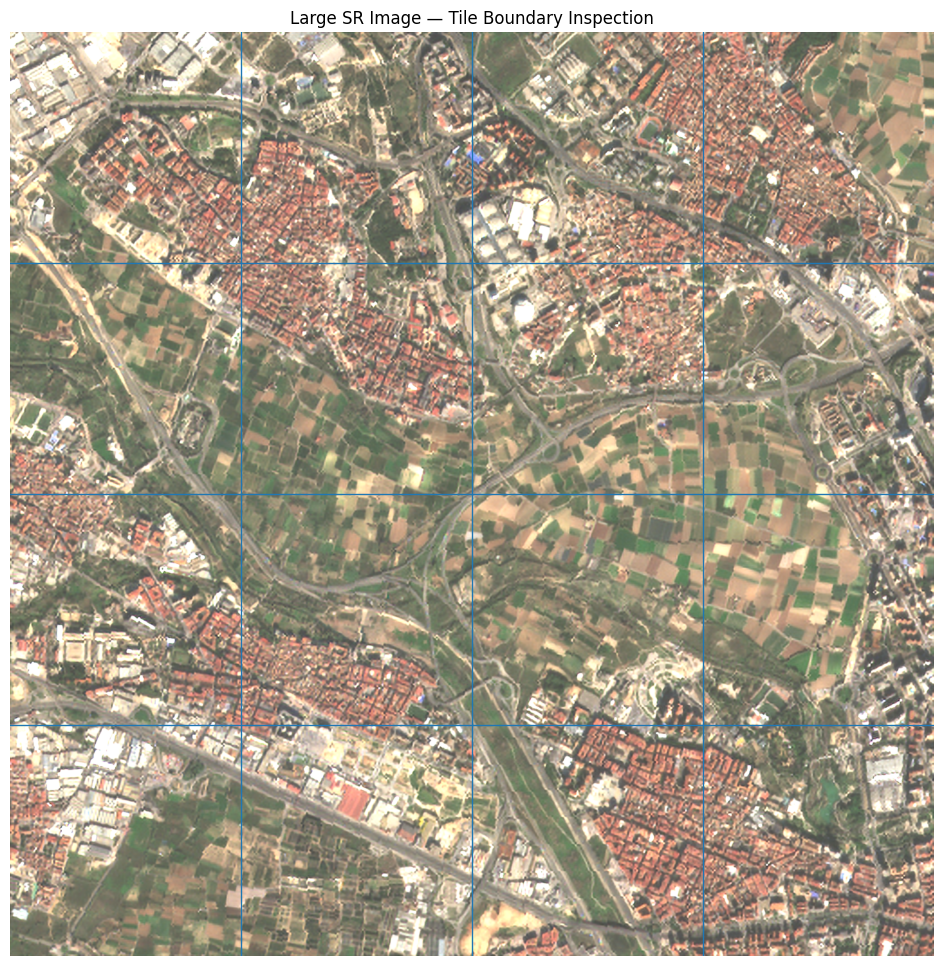

In [ ]:
plt.figure(figsize=(12, 12))

plt.imshow(large_sr_display)

# Draw approximate tile boundaries
for x in range(512, 2048, 512):
    plt.axvline(x, linewidth=1)

for y in range(512, 2048, 512):
    plt.axhline(y, linewidth=1)

plt.title("Large SR Image — Tile Boundary Inspection")
plt.axis("off")
plt.show()

###Get the original geospatial information

Our large_sample already contains the spatial metadata from cubo. Let's inspect it first.

In [ ]:
# Inspect spatial/geographic information
print("Dimensions:")
print(large_sample.dims)

print("\nCoordinates:")
print(large_sample.coords)

print("\nAttributes:")
print(large_sample.attrs)

Dimensions:
('band', 'y', 'x')

Coordinates:
Coordinates:
  * band                                     (band) <U3 48B 'B04' ... 'B08'
  * y                                        (y) float64 4kB 4.377e+06 ... 4....
  * x                                        (x) float64 4kB 7.184e+05 ... 7....
    time                                     datetime64[ns] 8B 2023-01-05T10:...
    id                                       <U54 216B 'S2A_MSIL2A_20230105T1...
    s2:datatake_id                           <U34 136B 'GS2A_20230105T105431_...
    instruments                              <U3 12B 'msi'
    s2:product_uri                           <U65 260B 'S2A_MSIL2A_20230105T1...
    s2:processing_baseline                   <U5 20B '04.00'
    s2:granule_id                            <U62 248B 'S2A_OPER_MSI_L2A_TL_E...
    s2:cloud_shadow_percentage               float64 8B 0.2227
    s2:mgrs_tile                             <U5 20B '31SBD'
    sat:relative_orbit                       int64 8B 5

###Export SEN2SR as GeoTIFF

In [ ]:
import rasterio
from rasterio.transform import Affine

# --------------------------------------------------
# Get spatial information from the original image
# --------------------------------------------------

# x/y coordinates of the original 10 m grid
x_coords = large_sample.x.values
y_coords = large_sample.y.values

# Original pixel size
x_resolution = abs(float(x_coords[1] - x_coords[0]))
y_resolution = abs(float(y_coords[1] - y_coords[0]))

print("Original X resolution:", x_resolution)
print("Original Y resolution:", y_resolution)

# --------------------------------------------------
# Calculate 2.5 m SR resolution
# --------------------------------------------------

scale_factor = 4

sr_x_resolution = x_resolution / scale_factor
sr_y_resolution = y_resolution / scale_factor

print("SR X resolution:", sr_x_resolution)
print("SR Y resolution:", sr_y_resolution)

# --------------------------------------------------
# Determine spatial bounds
# --------------------------------------------------

x_min = float(x_coords.min())
x_max = float(x_coords.max())
y_min = float(y_coords.min())
y_max = float(y_coords.max())

print("\nSpatial extent:")
print("X:", x_min, "to", x_max)
print("Y:", y_min, "to", y_max)

Original X resolution: 10.0
Original Y resolution: 10.0
SR X resolution: 2.5
SR Y resolution: 2.5

Spatial extent:
X: 718370.0 to 723480.0
Y: 4371930.0 to 4377040.0


###Create the 2.5 m GeoTIFF

In [ ]:
!pip install -q rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.1 MB/s eta 0:00:00


In [ ]:
import rioxarray
print("rioxarray loaded successfully")

rioxarray loaded successfully


In [ ]:
print("Has .rio accessor:", hasattr(large_sample, "rio"))

Has .rio accessor: True


In [ ]:
import rasterio
from rasterio.transform import from_origin

# ============================================================
# ORIGINAL SENTINEL-2 GRID
# ============================================================

original_resolution = float(large_sample.attrs["resolution"])
epsg_code = int(large_sample.attrs["epsg"])

x_coords = large_sample.x.values
y_coords = large_sample.y.values

# ============================================================
# SR GRID
# ============================================================

scale_factor = 4
sr_resolution = original_resolution / scale_factor

height = large_sr_numpy.shape[1]
width = large_sr_numpy.shape[2]

print("Original resolution:", original_resolution)
print("SR resolution:", sr_resolution)
print("EPSG:", epsg_code)
print("SR dimensions:", width, "x", height)

# ============================================================
# IMPORTANT:
# x/y coordinates represent PIXEL CENTERS.
#
# Original extent:
# X centers: 718370 ... 723480
# Y centers: 4377040 ... 4371930
#
# Therefore the outer edges are ±5 m from the centers.
# ============================================================

half_pixel = original_resolution / 2

left = float(x_coords.min()) - half_pixel
right = float(x_coords.max()) + half_pixel

bottom = float(y_coords.min()) - half_pixel
top = float(y_coords.max()) + half_pixel

print("\nOriginal spatial extent:")
print("Left:", left)
print("Right:", right)
print("Bottom:", bottom)
print("Top:", top)

# ============================================================
# CREATE EXACT 2.5 m TRANSFORM
# ============================================================

transform = from_origin(
    left,
    top,
    sr_resolution,
    sr_resolution
)

print("\nSR transform:")
print(transform)

# ============================================================
# PREPARE DATA
# ============================================================

sr_data = large_sr_numpy.copy()

# Original y coordinates go from north → south,
# so the SR array already follows the normal raster orientation.
print("\nSR data shape:", sr_data.shape)

# ============================================================
# WRITE GEOTIFF
# ============================================================

output_path = "/content/SEN2SR_2.5m_RGBN.tif"

with rasterio.open(
    output_path,
    "w",
    driver="GTiff",
    height=height,
    width=width,
    count=4,
    dtype="float32",
    crs=f"EPSG:{epsg_code}",
    transform=transform,
    compress="deflate"
) as dst:

    # B04 — Red
    dst.write(sr_data[0].astype("float32"), 1)

    # B03 — Green
    dst.write(sr_data[1].astype("float32"), 2)

    # B02 — Blue
    dst.write(sr_data[2].astype("float32"), 3)

    # B08 — NIR
    dst.write(sr_data[3].astype("float32"), 4)

    # Band descriptions
    dst.set_band_description(1, "B04 Red")
    dst.set_band_description(2, "B03 Green")
    dst.set_band_description(3, "B02 Blue")
    dst.set_band_description(4, "B08 NIR")

print("\n✅ Corrected GeoTIFF created:")
print(output_path)

Original resolution: 10.0
SR resolution: 2.5
EPSG: 32630
SR dimensions: 2048 x 2048

Original spatial extent:
Left: 718365.0
Right: 723485.0
Bottom: 4371925.0
Top: 4377045.0

SR transform:
| 2.50, 0.00, 718365.00|
| 0.00,-2.50, 4377045.00|
| 0.00, 0.00, 1.00|

SR data shape: (4, 2048, 2048)

✅ Corrected GeoTIFF created:
/content/SEN2SR_2.5m_RGBN.tif


In [ ]:
with rasterio.open("/content/SEN2SR_2.5m_RGBN.tif") as src:

    print("========== FINAL GEOTIFF VERIFICATION ==========")

    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)

    print("\nCRS:", src.crs)

    print("\nResolution:", src.res)

    print("\nBounds:")
    print(src.bounds)

    print("\nBand names:")
    for i in range(1, src.count + 1):
        print(i, src.descriptions[i - 1])

========== FINAL GEOTIFF VERIFICATION ==========
Width: 2048
Height: 2048
Bands: 4

CRS: EPSG:32630

Resolution: (2.5, 2.5)

Bounds:
BoundingBox(left=718365.0, bottom=4371925.0, right=723485.0, top=4377045.0)

Band names:
1 B04 Red
2 B03 Green
3 B02 Blue
4 B08 NIR


First, let's diagnose exactly what cubo gave us

In [ ]:
# Check the exact spatial metadata from cubo

print("========== CUBO METADATA ==========")

print("\nAttributes:")
for key, value in large_sample.attrs.items():
    print(f"{key}: {value}")

print("\nX coordinates:")
print("First:", large_sample.x.values[0])
print("Second:", large_sample.x.values[1])
print("Difference:", large_sample.x.values[1] - large_sample.x.values[0])

print("\nY coordinates:")
print("First:", large_sample.y.values[0])
print("Second:", large_sample.y.values[1])
print("Difference:", large_sample.y.values[1] - large_sample.y.values[0])

========== CUBO METADATA ==========

Attributes:
collection: sentinel-2-l2a
stac: https://planetarycomputer.microsoft.com/api/stac/v1
epsg: 32630
resolution: 10
edge_size: 512
edge_size_m: 5120
central_lat: 39.49152740347753
central_lon: -0.4308725142800361
central_y: 4374475.482118196
central_x: 720932.169328265
time_coverage_start: 2023-01-01
time_coverage_end: 2023-12-31

X coordinates:
First: 718370.0
Second: 718380.0
Difference: 10.0

Y coordinates:
First: 4377040.0
Second: 4377030.0
Difference: -10.0


###Verify geospatial alignment

In [ ]:
import rasterio
import numpy as np

input_x = large_sample.x.values
input_y = large_sample.y.values

original_res = float(large_sample.attrs["resolution"])
sr_res = original_res / 4

# Original raster bounds from pixel centers
original_bounds = (
    float(input_x.min()) - original_res / 2,
    float(input_y.min()) - original_res / 2,
    float(input_x.max()) + original_res / 2,
    float(input_y.max()) + original_res / 2
)

with rasterio.open("/content/SEN2SR_2.5m_RGBN.tif") as src:

    sr_bounds = (
        src.bounds.left,
        src.bounds.bottom,
        src.bounds.right,
        src.bounds.top
    )

    print("========== GEOSPATIAL VERIFICATION ==========")

    print("\nOriginal resolution:")
    print(original_res, "m")

    print("\nSR resolution:")
    print(src.res, "m")

    print("\nOriginal CRS:")
    print(f"EPSG:{large_sample.attrs['epsg']}")

    print("\nSR CRS:")
    print(src.crs)

    print("\nOriginal bounds:")
    print(original_bounds)

    print("\nSR bounds:")
    print(sr_bounds)

    print("\nOriginal dimensions:")
    print(len(input_x), "x", len(input_y))

    print("\nSR dimensions:")
    print(src.width, "x", src.height)

    # Compare bounds
    bound_difference = np.array(sr_bounds) - np.array(original_bounds)

    print("\nBound differences:")
    print(bound_difference)

    print("\nMaximum spatial difference:")
    print(np.max(np.abs(bound_difference)), "m")

========== GEOSPATIAL VERIFICATION ==========

Original resolution:
10.0 m

SR resolution:
(2.5, 2.5) m

Original CRS:
EPSG:32630

SR CRS:
EPSG:32630

Original bounds:
(718365.0, 4371925.0, 723485.0, 4377045.0)

SR bounds:
(718365.0, 4371925.0, 723485.0, 4377045.0)

Original dimensions:
512 x 512

SR dimensions:
2048 x 2048

Bound differences:
[0. 0. 0. 0.]

Maximum spatial difference:
0.0 m


###Check the 4× relationship

Now let's mathematically verify that our output dimensions make sense.

In [ ]:
expected_width = len(input_x) * 4
expected_height = len(input_y) * 4

with rasterio.open("/content/SEN2SR_2.5m_RGBN.tif") as src:

    print("========== SCALE VERIFICATION ==========")

    print("Expected width :", expected_width)
    print("Actual width   :", src.width)

    print("Expected height:", expected_height)
    print("Actual height  :", src.height)

    print("\nExpected resolution:", sr_res)
    print("Actual resolution  :", src.res)

    width_ok = src.width == expected_width
    height_ok = src.height == expected_height

    resolution_ok = (
        np.isclose(src.res[0], sr_res) and
        np.isclose(src.res[1], sr_res)
    )

    print("\nWidth correct      :", width_ok)
    print("Height correct     :", height_ok)
    print("Resolution correct :", resolution_ok)

    if width_ok and height_ok and resolution_ok:
        print("\n✅ 4× spatial scaling verified!")
    else:
        print("\n⚠️ Check the GeoTIFF geometry.")

========== SCALE VERIFICATION ==========
Expected width : 2048
Actual width   : 2048
Expected height: 2048
Actual height  : 2048

Expected resolution: 2.5
Actual resolution  : (2.5, 2.5)

Width correct      : True
Height correct     : True
Resolution correct : True

✅ 4× spatial scaling verified!


Geospatial Alignment Verification 🌍

We want to prove that the SR image covers exactly the same physical area as the original Sentinel-2 image.

In [ ]:
import rasterio
import numpy as np

# --------------------------------------------------
# Open the SR GeoTIFF
# --------------------------------------------------

with rasterio.open("/content/SEN2SR_2.5m_RGBN.tif") as sr:

    sr_bounds = sr.bounds
    sr_crs = sr.crs
    sr_resolution = sr.res

# --------------------------------------------------
# Calculate ORIGINAL Sentinel-2 bounds
# --------------------------------------------------

original_resolution = float(
    large_sample.attrs["resolution"]
)

x_coords = large_sample.x.values
y_coords = large_sample.y.values

half_pixel = original_resolution / 2

original_left = float(x_coords.min()) - half_pixel
original_right = float(x_coords.max()) + half_pixel

original_bottom = float(y_coords.min()) - half_pixel
original_top = float(y_coords.max()) + half_pixel

# --------------------------------------------------
# Print comparison
# --------------------------------------------------

print("========== GEOSPATIAL ALIGNMENT ==========")

print("\nOriginal Sentinel-2 bounds:")
print("Left  :", original_left)
print("Bottom:", original_bottom)
print("Right :", original_right)
print("Top   :", original_top)

print("\nSR GeoTIFF bounds:")
print("Left  :", sr_bounds.left)
print("Bottom:", sr_bounds.bottom)
print("Right :", sr_bounds.right)
print("Top   :", sr_bounds.top)

print("\nCRS:")
print("Original EPSG:", large_sample.attrs["epsg"])
print("SR CRS       :", sr_crs)

print("\nResolution:")
print("Original:", original_resolution, "m")
print("SR      :", sr_resolution)

# --------------------------------------------------
# Compare bounds
# --------------------------------------------------

tolerance = 0.01

left_ok = np.isclose(
    original_left,
    sr_bounds.left,
    atol=tolerance
)

right_ok = np.isclose(
    original_right,
    sr_bounds.right,
    atol=tolerance
)

bottom_ok = np.isclose(
    original_bottom,
    sr_bounds.bottom,
    atol=tolerance
)

top_ok = np.isclose(
    original_top,
    sr_bounds.top,
    atol=tolerance
)

crs_ok = str(sr_crs) == f"EPSG:{large_sample.attrs['epsg']}"

print("\n========== RESULTS ==========")
print("Left aligned   :", left_ok)
print("Right aligned  :", right_ok)
print("Bottom aligned :", bottom_ok)
print("Top aligned    :", top_ok)
print("CRS correct    :", crs_ok)

if all([left_ok, right_ok, bottom_ok, top_ok, crs_ok]):
    print("\n✅ GEOSPATIAL ALIGNMENT VERIFIED!")
else:
    print("\n⚠️ Geospatial alignment needs correction.")

========== GEOSPATIAL ALIGNMENT ==========

Original Sentinel-2 bounds:
Left  : 718365.0
Bottom: 4371925.0
Right : 723485.0
Top   : 4377045.0

SR GeoTIFF bounds:
Left  : 718365.0
Bottom: 4371925.0
Right : 723485.0
Top   : 4377045.0

CRS:
Original EPSG: 32630
SR CRS       : EPSG:32630

Resolution:
Original: 10.0 m
SR      : (2.5, 2.5)

========== RESULTS ==========
Left aligned   : True
Right aligned  : True
Bottom aligned : True
Top aligned    : True
CRS correct    : True

✅ GEOSPATIAL ALIGNMENT VERIFIED!


###Spectral Fidelity Validation 🧪

Our question is:

Did SEN2SR create sharper spatial detail while keeping the spectral behavior of the original Sentinel-2 image reasonably consistent?

We'll test this using NDVI.

####Calculate original and SR NDVI

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize

# ============================================================
# ORIGINAL SENTINEL-2
# ============================================================

red_original = large_s2_numpy[0]   # B04
nir_original = large_s2_numpy[3]   # B08

ndvi_original = (
    (nir_original - red_original) /
    (nir_original + red_original + 1e-8)
)

# ============================================================
# SEN2SR
# ============================================================

red_sr = large_sr_numpy[0]         # B04
nir_sr = large_sr_numpy[3]         # B08

ndvi_sr = (
    (nir_sr - red_sr) /
    (nir_sr + red_sr + 1e-8)
)

# Limit NDVI to physical range
ndvi_original = np.clip(ndvi_original, -1, 1)
ndvi_sr = np.clip(ndvi_sr, -1, 1)

print("Original NDVI:", ndvi_original.shape)
print("SR NDVI:", ndvi_sr.shape)

Original NDVI: (512, 512)
SR NDVI: (2048, 2048)


###Convert SR NDVI back to the original grid

In [ ]:
# Downsample SR NDVI to the original 10 m grid

ndvi_sr_10m = resize(
    ndvi_sr,
    ndvi_original.shape,
    order=1,
    preserve_range=True,
    anti_aliasing=True
)

ndvi_sr_10m = np.clip(
    ndvi_sr_10m,
    -1,
    1
)

print("SR NDVI on 10m grid:", ndvi_sr_10m.shape)

SR NDVI on 10m grid: (512, 512)


###Calculate MAE, RMSE and correlation

In [ ]:
# Flatten the images
original_flat = ndvi_original.flatten()
sr_flat = ndvi_sr_10m.flatten()

# Remove invalid pixels
valid = (
    np.isfinite(original_flat) &
    np.isfinite(sr_flat)
)

original_flat = original_flat[valid]
sr_flat = sr_flat[valid]

# ------------------------------------------------------------
# MAE
# ------------------------------------------------------------

mae = np.mean(
    np.abs(original_flat - sr_flat)
)

# ------------------------------------------------------------
# RMSE
# ------------------------------------------------------------

rmse = np.sqrt(
    np.mean(
        (original_flat - sr_flat) ** 2
    )
)

# ------------------------------------------------------------
# Correlation
# ------------------------------------------------------------

correlation = np.corrcoef(
    original_flat,
    sr_flat
)[0, 1]

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("========== NDVI SPECTRAL FIDELITY ==========")

print("Valid pixels:", len(original_flat))

print("\nMAE :", mae)
print("RMSE:", rmse)
print("Correlation:", correlation)

========== NDVI SPECTRAL FIDELITY ==========
Valid pixels: 262144

MAE : 0.0065168752
RMSE: 0.008820633
Correlation: 0.9987464984456854


###Visualize the spectral difference

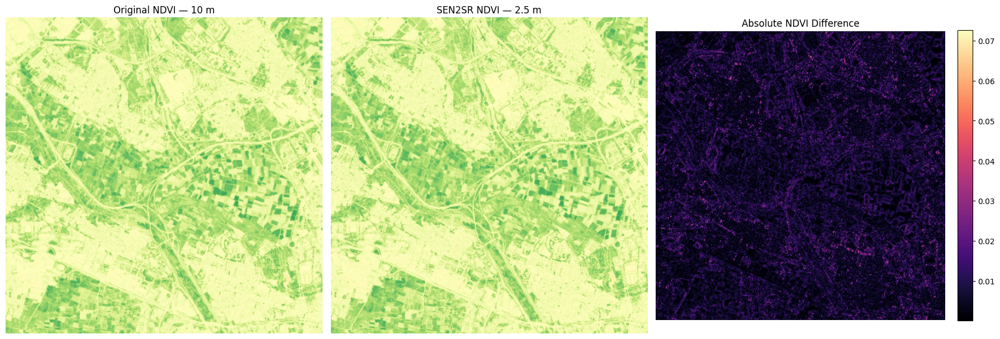

In [ ]:
ndvi_difference = np.abs(
    ndvi_original - ndvi_sr_10m
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

axes[0].imshow(
    ndvi_original,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

axes[0].set_title(
    "Original NDVI — 10 m"
)
axes[0].axis("off")


axes[1].imshow(
    ndvi_sr,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

axes[1].set_title(
    "SEN2SR NDVI — 2.5 m"
)
axes[1].axis("off")


im = axes[2].imshow(
    ndvi_difference,
    cmap="magma"
)

axes[2].set_title(
    "Absolute NDVI Difference"
)
axes[2].axis("off")

plt.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04
)

plt.tight_layout()
plt.show()

###Cloud Masking
the final system should be:

    Sentinel-2 L2A
      ↓
    Cloud filtering
      ↓
    Cloud masking
      ↓
    Normalization
      ↓
    SEN2SR

This matters because otherwise the AI may try to super-resolve clouds, cloud shadows, or other contaminated pixels.

We'll use Sentinel-2's Scene Classification Layer (SCL).

Important SCL classes include:

    3  → Cloud shadow
    8  → Medium-probability cloud
    9  → High-probability cloud
    10 → Cirrus
    11 → Snow/ice

We'll mask those

####Create a cloud-aware Sentinel-2 cube

We need to retrieve the SCL band in addition to our four model bands.

In [ ]:
import cubo

cloud_da = cubo.create(
    lat=39.49152740347753,
    lon=-0.4308725142800361,
    collection="sentinel-2-l2a",

    # 4 model bands + Scene Classification Layer
    bands=["B04", "B03", "B02", "B08", "SCL"],

    start_date="2023-01-01",
    end_date="2023-12-31",

    edge_size=512,
    resolution=10,

    # Prefer relatively cloud-free scenes
    query={
        "eo:cloud_cover": {
            "lt": 20
        }
    }
)

print(cloud_da)

<xarray.DataArray 'sentinel-2-l2a' (time: 129, band: 5, y: 512, x: 512)> Size: 1GB
dask.array<fetch_raster_window, shape=(129, 5, 512, 512), dtype=float64, chunksize=(1, 1, 512, 512), chunktype=numpy.ndarray>
Coordinates: (12/44)
  * time                                     (time) datetime64[ns] 1kB 2023-0...
  * band                                     (band) <U3 60B 'B04' ... 'SCL'
  * y                                        (y) float64 4kB 4.377e+06 ... 4....
  * x                                        (x) float64 4kB 7.184e+05 ... 7....
    id                                       (time) <U54 28kB 'S2A_MSIL2A_202...
    s2:datatake_id                           (time) <U34 18kB 'GS2A_20230105T...
    ...                                       ...
    gsd                                      (band) float64 40B 10.0 ... 20.0
    common_name                              (band) object 40B 'red' ... None
    center_wavelength                        (band) object 40B 0.665 ... None
    f

See how many scenes remain

In [ ]:
print("Number of cloud-filtered scenes:", len(cloud_da.time))

print("\nAvailable scenes:")
for i, t in enumerate(cloud_da.time.values):
    print(i, t)

Number of cloud-filtered scenes: 129

Available scenes:
0 2023-01-05T10:54:31.024000000
1 2023-01-05T10:54:31.024000000
2 2023-01-10T10:53:29.024000000
3 2023-01-10T10:53:29.024000000
4 2023-01-10T10:53:29.024000000
5 2023-01-20T10:52:49.024000000
6 2023-01-20T10:52:49.024000000
7 2023-01-30T10:52:09.024000000
8 2023-01-30T10:52:09.024000000
9 2023-01-30T10:52:09.024000000
10 2023-02-04T10:52:41.024000000
11 2023-02-04T10:52:41.024000000
12 2023-02-04T10:52:41.024000000
13 2023-02-04T10:52:41.024000000
14 2023-03-01T10:48:59.025000000
15 2023-03-01T10:48:59.025000000
16 2023-03-16T10:48:01.024000000
17 2023-03-16T10:48:01.024000000
18 2023-03-16T10:48:01.024000000
19 2023-03-16T10:48:01.024000000
20 2023-04-05T10:50:31.024000000
21 2023-04-05T10:50:31.024000000
22 2023-04-05T10:50:31.024000000
23 2023-04-05T10:50:31.024000000
24 2023-04-20T10:46:19.024000000
25 2023-04-20T10:46:19.024000000
26 2023-04-20T10:46:19.024000000
27 2023-04-20T10:46:19.024000000
28 2023-05-05T10:46:21.0240000

Select one scene

In [ ]:
cloud_sample = cloud_da.isel(time=0)

print(cloud_sample)
#download it
cloud_data = cloud_sample.compute().to_numpy()

print("Cloud-aware data shape:", cloud_data.shape)

<xarray.DataArray 'sentinel-2-l2a' (band: 5, y: 512, x: 512)> Size: 10MB
dask.array<getitem, shape=(5, 512, 512), dtype=float64, chunksize=(1, 512, 512), chunktype=numpy.ndarray>
Coordinates: (12/44)
  * band                                     (band) <U3 60B 'B04' ... 'SCL'
  * y                                        (y) float64 4kB 4.377e+06 ... 4....
  * x                                        (x) float64 4kB 7.184e+05 ... 7....
    time                                     datetime64[ns] 8B 2023-01-05T10:...
    id                                       <U54 216B 'S2A_MSIL2A_20230105T1...
    s2:datatake_id                           <U34 136B 'GS2A_20230105T105431_...
    ...                                       ...
    gsd                                      (band) float64 40B 10.0 ... 20.0
    common_name                              (band) object 40B 'red' ... None
    center_wavelength                        (band) object 40B 0.665 ... None
    full_width_half_max            

Cloud-aware data shape: (5, 512, 512)


Examine the SCL classes

In [ ]:
scl = cloud_data[4]

unique_classes, counts = np.unique(
    scl,
    return_counts=True
)

print("========== SCL CLASSES ==========")

for cls, count in zip(unique_classes, counts):
    percentage = count / scl.size * 100

    print(
        f"Class {int(cls):2d} : "
        f"{count:7d} pixels "
        f"({percentage:.2f}%)"
    )

========== SCL CLASSES ==========
Class  2 :     303 pixels (0.12%)
Class  4 :   72683 pixels (27.73%)
Class  5 :  188660 pixels (71.97%)
Class  6 :     498 pixels (0.19%)


Create the cloud mask

In [ ]:
# --------------------------------------------------
# SCL cloud / contamination classes
# --------------------------------------------------

bad_classes = [
    3,   # Cloud shadow
    8,   # Medium probability cloud
    9,   # High probability cloud
    10,  # Cirrus
    11   # Snow / ice
]

cloud_mask = np.isin(
    scl,
    bad_classes
)

valid_mask = ~cloud_mask

print("Total pixels:", scl.size)
print("Masked pixels:", cloud_mask.sum())
print("Valid pixels:", valid_mask.sum())

print(
    "Masked percentage:",
    cloud_mask.mean() * 100,
    "%"
)

Total pixels: 262144
Masked pixels: 0
Valid pixels: 262144
Masked percentage: 0.0 %


Visualize the cloud mask

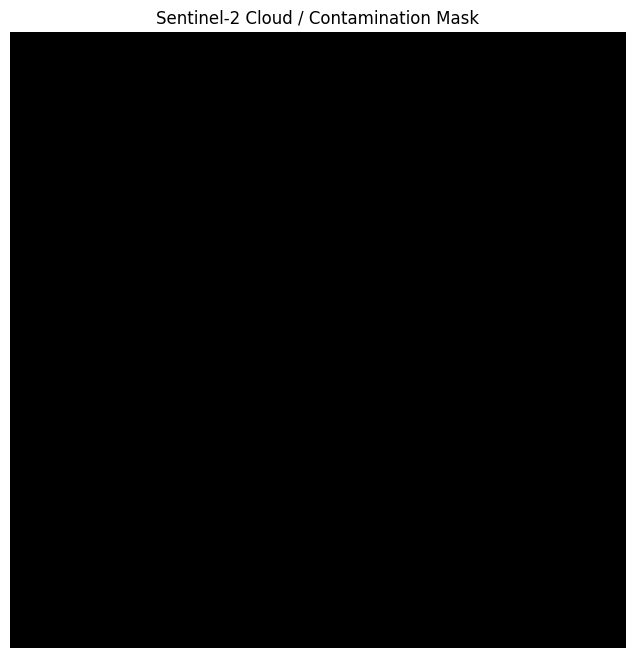

In [ ]:
plt.figure(figsize=(8, 8))

plt.imshow(
    cloud_mask,
    cmap="gray"
)

plt.title("Sentinel-2 Cloud / Contamination Mask")
plt.axis("off")

plt.show()

Create a clean 4-band Sentinel-2 input

In [ ]:
# Extract the 4 spectral bands
clean_s2 = cloud_data[:4].copy()

# Keep the validity mask separately
valid_mask = ~cloud_mask

# Make a copy for model input
masked_s2 = clean_s2.copy()

# Mask contaminated pixels
masked_s2[:, cloud_mask] = 0.0

print("Model input shape:", masked_s2.shape)
print("Valid pixels:", valid_mask.sum())
print("Masked pixels:", cloud_mask.sum())

Model input shape: (4, 512, 512)
Valid pixels: 262144
Masked pixels: 0


Visualize the cloud-masked Sentinel-2 image

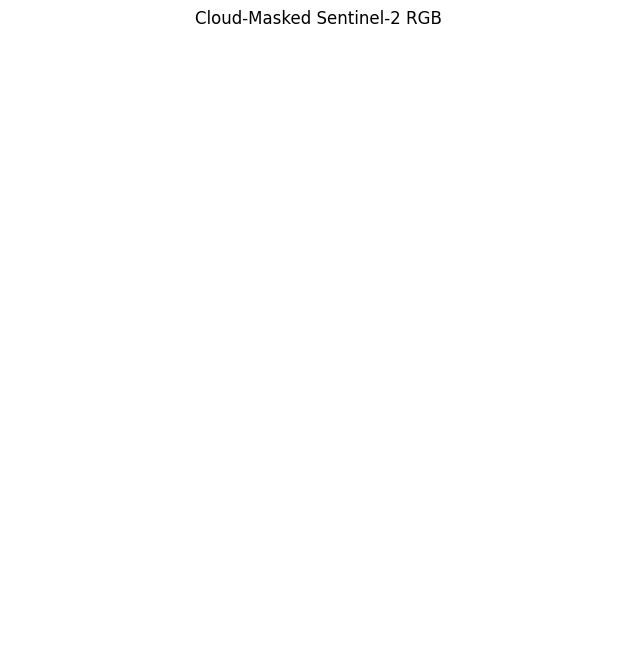

In [ ]:
rgb_masked = np.transpose(masked_s2[:3], (1, 2, 0))

plt.figure(figsize=(8, 8))
plt.imshow(np.clip(rgb_masked * 3, 0, 1))
plt.title("Cloud-Masked Sentinel-2 RGB")
plt.axis("off")
plt.show()

Run SEN2SR on the masked image

In [ ]:
X_masked = torch.from_numpy(masked_s2).float().to(device)

X_masked = torch.nan_to_num(
    X_masked,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

with torch.no_grad():
    masked_superX = sen2sr.predict_large(
        model=model,
        X=X_masked,
        overlap=32
    )

print("SR output shape:", masked_superX.shape)

100%|██████████| 36/36 [00:01<00:00, 35.53it/s]

SR output shape: torch.Size([4, 2048, 2048])


Upscale the validity mask

In [ ]:
# Convert 10m validity mask to 2.5m validity mask
valid_mask_25m = np.repeat(
    np.repeat(valid_mask, 4, axis=0),
    4,
    axis=1
)

print("Original mask:", valid_mask.shape)
print("2.5m mask:", valid_mask_25m.shape)

print("Valid 2.5m pixels:", valid_mask_25m.sum())
print("Invalid 2.5m pixels:", (~valid_mask_25m).sum())

Original mask: (512, 512)
2.5m mask: (2048, 2048)
Valid 2.5m pixels: 4194304
Invalid 2.5m pixels: 0


Apply the mask to the SR result

Convert the model output to NumPy first:

In [ ]:
masked_sr_numpy = masked_superX.detach().cpu().numpy()

print("SR shape:", masked_sr_numpy.shape)

SR shape: (4, 2048, 2048)


In [ ]:
# Create a masked copy
cloud_aware_sr = masked_sr_numpy.copy()

# Mark cloud/invalid regions as 0
cloud_aware_sr[:, ~valid_mask_25m] = 0.0

print("Cloud-aware SR shape:", cloud_aware_sr.shape)

Cloud-aware SR shape: (4, 2048, 2048)


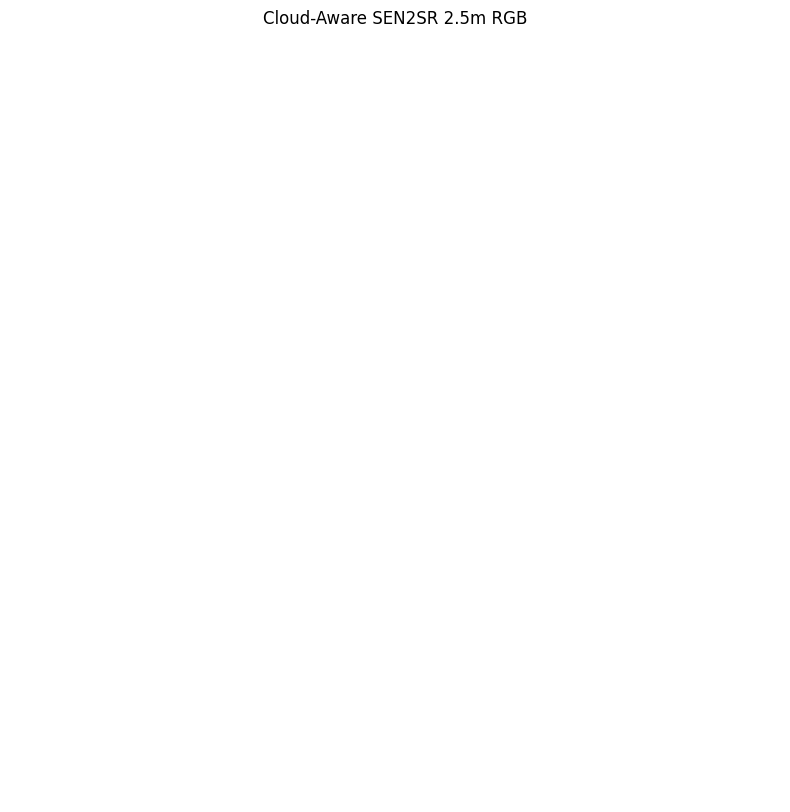

In [ ]:
#visualize it
sr_rgb_cloud_aware = np.transpose(
    cloud_aware_sr[:3],
    (1, 2, 0)
)

plt.figure(figsize=(10, 10))
plt.imshow(np.clip(sr_rgb_cloud_aware * 3, 0, 1))
plt.title("Cloud-Aware SEN2SR 2.5m RGB")
plt.axis("off")
plt.show()

In [ ]:
print("SR minimum:", cloud_aware_sr.min())
print("SR maximum:", cloud_aware_sr.max())
print("SR mean:", cloud_aware_sr.mean())

print("\nPercentiles:")
print("1% :", np.percentile(cloud_aware_sr, 1))
print("50%:", np.percentile(cloud_aware_sr, 50))
print("99%:", np.percentile(cloud_aware_sr, 99))

SR minimum: 173.97784
SR maximum: 13776.514
SR mean: 2269.6482

Percentiles:
1% : 1069.946
50%: 2001.4688
99%: 5253.3223


In [ ]:
# Convert SEN2SR output from Sentinel-2 scale to reflectance
cloud_aware_sr_reflectance = cloud_aware_sr / 10000.0

print("SR reflectance:")
print("Min:", cloud_aware_sr_reflectance.min())
print("Max:", cloud_aware_sr_reflectance.max())
print("Mean:", cloud_aware_sr_reflectance.mean())

SR reflectance:
Min: 0.017397784
Max: 1.3776513
Mean: 0.22696501


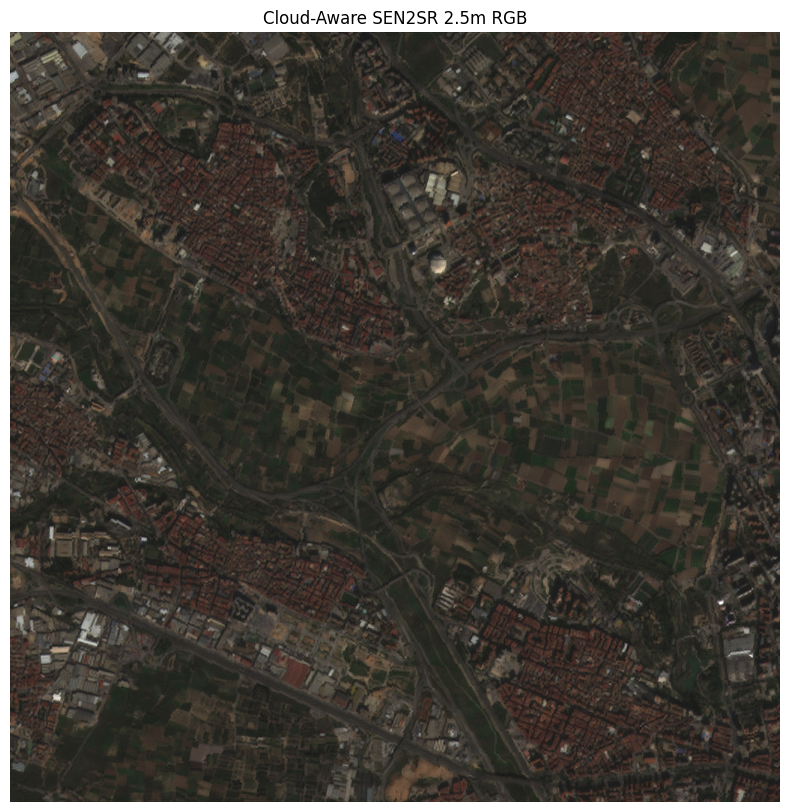

In [ ]:
sr_rgb_cloud_aware = np.transpose(
    cloud_aware_sr_reflectance[:3],
    (1, 2, 0)
)

plt.figure(figsize=(10, 10))

plt.imshow(
    np.clip(sr_rgb_cloud_aware, 0, 1)
)

plt.title("Cloud-Aware SEN2SR 2.5m RGB")
plt.axis("off")
plt.show()

In [ ]:
print("Original reflectance")
print("Min:", large_s2_numpy.min())
print("Max:", large_s2_numpy.max())
print("Mean:", large_s2_numpy.mean())

print("\nSR reflectance")
print("Min:", cloud_aware_sr_reflectance.min())
print("Max:", cloud_aware_sr_reflectance.max())
print("Mean:", cloud_aware_sr_reflectance.mean())

Original reflectance
Min: 0.0674
Max: 1.3608
Mean: 0.22696677

SR reflectance
Min: 0.017397784
Max: 1.3776513
Mean: 0.22696501


###Export Cloud-Aware GeoTIFF

In [ ]:
import rasterio
from rasterio.transform import from_origin

# --------------------------------------------------
# 1. Convert reflectance back to Sentinel-2 scale
# --------------------------------------------------

sr_uint16 = np.clip(
    cloud_aware_sr_reflectance * 10000,
    0,
    65535
).astype(np.uint16)


# --------------------------------------------------
# 2. Get original 10m spatial coordinates
# --------------------------------------------------

x_coords = cloud_sample.x.values
y_coords = cloud_sample.y.values

# Pixel-center coordinates → outer bounds
xmin = x_coords.min() - 5
xmax = x_coords.max() + 5

ymin = y_coords.min() - 5
ymax = y_coords.max() + 5

# 2.5m transform
transform_25m = from_origin(
    xmin,
    ymax,
    2.5,
    2.5
)


# --------------------------------------------------
# 3. Output file
# --------------------------------------------------

output_path = "/content/SEN2SR_CloudAware_2.5m_RGBN.tif"


# --------------------------------------------------
# 4. Write GeoTIFF
# --------------------------------------------------

with rasterio.open(
    output_path,
    "w",
    driver="GTiff",
    height=2048,
    width=2048,
    count=5,
    dtype="uint16",
    crs="EPSG:32630",
    transform=transform_25m,
    nodata=0,
    compress="deflate"
) as dst:

    # RGB + NIR
    dst.write(sr_uint16[0], 1)
    dst.write(sr_uint16[1], 2)
    dst.write(sr_uint16[2], 3)
    dst.write(sr_uint16[3], 4)

    # Validity mask
    dst.write(valid_mask_25m.astype(np.uint16), 5)

    # Band descriptions
    dst.set_band_description(1, "B04 Red")
    dst.set_band_description(2, "B03 Green")
    dst.set_band_description(3, "B02 Blue")
    dst.set_band_description(4, "B08 NIR")
    dst.set_band_description(5, "Validity Mask")

print("✅ GeoTIFF exported!")
print(output_path)

✅ GeoTIFF exported!
/content/SEN2SR_CloudAware_2.5m_RGBN.tif


Verify the file

In [ ]:
with rasterio.open(output_path) as src:

    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data type:", src.dtypes)
    print("NoData:", src.nodata)

    print("\nBand descriptions:")
    for i in range(1, src.count + 1):
        print(i, "→", src.descriptions[i-1])

Width: 2048
Height: 2048
Bands: 5
CRS: EPSG:32630
Resolution: (2.5, 2.5)
Data type: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16')
NoData: 0.0

Band descriptions:
1 → B04 Red
2 → B03 Green
3 → B02 Blue
4 → B08 NIR
5 → Validity Mask


We're now at:

    Sentinel-2 L2A
     │
     ▼
    10m RGB + NIR
     │
     ▼
    Cloud / SCL Detection
     │
     ▼
    Validity Mask
     │
     ▼
    SEN2SRLite
     │
     ▼
    4× Super Resolution
     │
     ▼
    2.5m RGB + NIR
     │
     ├───────────────┐
     ▼               ▼
    SR Image        Validity Mask
     │               │
     └───────┬───────┘
             ▼
     Cloud-Aware GeoTIFF

Quantitative SR Quality Assessment

We shouldn't only say:

    "Our SR image looks sharper."

We need numbers.

However, there's an important scientific distinction:

    Sentinel-2 10 m → SR 2.5 m → back to 10 m → compare with Sentinel-2 10 m

tests consistency, but it is not true 2.5 m ground-truth validation.

So we'll first establish a baseline comparison:
This lets us quantify whether SEN2SR preserves the original observation better than a simple interpolation baseline.

In [ ]:
from skimage.transform import resize
import numpy as np

# Create bicubic 4x upsampled baseline
bicubic_25m = np.zeros((4, 2048, 2048), dtype=np.float32)

for b in range(4):
    bicubic_25m[b] = resize(
        large_s2_numpy[b],
        (2048, 2048),
        order=3,              # Bicubic
        preserve_range=True,
        anti_aliasing=False
    )

print("Bicubic shape:", bicubic_25m.shape)

Bicubic shape: (4, 2048, 2048)


###Downsample both products back to 10 m

We'll use area averaging because we're asking:

"If our 2.5 m product is aggregated back to the original 10 m scale, how well does it reproduce the Sentinel-2 observation?"

In [ ]:
# Downsample SEN2SR and bicubic products back to 512x512

sen2sr_10m = np.zeros((4, 512, 512), dtype=np.float32)
bicubic_10m = np.zeros((4, 512, 512), dtype=np.float32)

for b in range(4):

    sen2sr_10m[b] = resize(
        cloud_aware_sr_reflectance[b],
        (512, 512),
        order=1,
        preserve_range=True,
        anti_aliasing=True
    )

    bicubic_10m[b] = resize(
        bicubic_25m[b],
        (512, 512),
        order=1,
        preserve_range=True,
        anti_aliasing=True
    )

print("SEN2SR back to 10m:", sen2sr_10m.shape)
print("Bicubic back to 10m:", bicubic_10m.shape)

SEN2SR back to 10m: (4, 512, 512)
Bicubic back to 10m: (4, 512, 512)


Calculate MAE and RMSE

We'll compare only valid pixels so clouds don't distort our measurements.

In [ ]:
# Valid pixels from the original 10m grid
valid_pixels = valid_mask

metrics = {}

for name, prediction in [
    ("SEN2SR", sen2sr_10m),
    ("Bicubic", bicubic_10m)
]:

    maes = []
    rmses = []
    correlations = []

    for b in range(4):

        reference = large_s2_numpy[b][valid_pixels]
        pred = prediction[b][valid_pixels]

        mae = np.mean(np.abs(reference - pred))
        rmse = np.sqrt(np.mean((reference - pred) ** 2))

        correlation = np.corrcoef(
            reference,
            pred
        )[0, 1]

        maes.append(mae)
        rmses.append(rmse)
        correlations.append(correlation)

    metrics[name] = {
        "MAE": maes,
        "RMSE": rmses,
        "Correlation": correlations
    }

print("Metrics calculated successfully!")

Metrics calculated successfully!


In [ ]:
#Print the results
band_names = ["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]

for method in metrics:

    print("\n==============================")
    print(method)
    print("==============================")

    for i, band in enumerate(band_names):

        print(
            f"{band:10s} | "
            f"MAE: {metrics[method]['MAE'][i]:.6f} | "
            f"RMSE: {metrics[method]['RMSE'][i]:.6f} | "
            f"Correlation: {metrics[method]['Correlation'][i]:.4f}"
        )



SEN2SR
B04 Red    | MAE: 0.003636 | RMSE: 0.005013 | Correlation: 0.9982
B03 Green  | MAE: 0.003588 | RMSE: 0.005250 | Correlation: 0.9968
B02 Blue   | MAE: 0.002898 | RMSE: 0.004334 | Correlation: 0.9972
B08 NIR    | MAE: 0.005756 | RMSE: 0.007610 | Correlation: 0.9974

Bicubic
B04 Red    | MAE: 0.006251 | RMSE: 0.008891 | Correlation: 0.9935
B03 Green  | MAE: 0.005009 | RMSE: 0.007453 | Correlation: 0.9931
B02 Blue   | MAE: 0.004260 | RMSE: 0.006513 | Correlation: 0.9933
B08 NIR    | MAE: 0.008224 | RMSE: 0.011029 | Correlation: 0.9940


How to interpret it

For this consistency test:

Lower MAE → closer to original Sentinel-2 observation
Lower RMSE → fewer/lower reconstruction errors
Correlation closer to 1 → stronger preservation of spatial/spectral variation

But don't automatically assume SEN2SR must beat bicubic on every metric. The result itself is what we'll report.

###Calculate original NDVI

In [ ]:
# Original Sentinel-2 NDVI at 10m

red_10m = large_s2_numpy[0]
nir_10m = large_s2_numpy[3]

ndvi_original = (
    (nir_10m - red_10m) /
    (nir_10m + red_10m + 1e-8)
)

# Keep only physically meaningful NDVI range
ndvi_original = np.clip(ndvi_original, -1, 1)

print("Original NDVI shape:", ndvi_original.shape)
print("NDVI min:", ndvi_original.min())
print("NDVI max:", ndvi_original.max())
print("NDVI mean:", ndvi_original[valid_mask].mean())

Original NDVI shape: (512, 512)
NDVI min: -0.33770493
NDVI max: 0.7251037
NDVI mean: 0.19958033


Calculate NDVI from the 2.5 m SEN2SR product

Use the reflectance-scaled SR data:

In [ ]:
# SEN2SR NDVI at 2.5m

red_sr = cloud_aware_sr_reflectance[0]
nir_sr = cloud_aware_sr_reflectance[3]

ndvi_sr_25m = (
    (nir_sr - red_sr) /
    (nir_sr + red_sr + 1e-8)
)

ndvi_sr_25m = np.clip(ndvi_sr_25m, -1, 1)

print("SR NDVI shape:", ndvi_sr_25m.shape)
print("SR NDVI min:", ndvi_sr_25m.min())
print("SR NDVI max:", ndvi_sr_25m.max())

SR NDVI shape: (2048, 2048)
SR NDVI min: -0.52683234
SR NDVI max: 0.8955732


Bring SR NDVI back to 10 m

Now we compare apples with apples:

In [ ]:
from skimage.transform import resize

ndvi_sr_10m = resize(
    ndvi_sr_25m,
    (512, 512),
    order=1,
    preserve_range=True,
    anti_aliasing=True
).astype(np.float32)

print("SR NDVI converted to 10m:", ndvi_sr_10m.shape)

SR NDVI converted to 10m: (512, 512)


Calculate NDVI metrics

In [ ]:
# Compare only valid pixels

reference_ndvi = ndvi_original[valid_mask]
predicted_ndvi = ndvi_sr_10m[valid_mask]

ndvi_mae = np.mean(
    np.abs(reference_ndvi - predicted_ndvi)
)

ndvi_rmse = np.sqrt(
    np.mean((reference_ndvi - predicted_ndvi) ** 2)
)

ndvi_correlation = np.corrcoef(
    reference_ndvi,
    predicted_ndvi
)[0, 1]

ndvi_bias = np.mean(
    predicted_ndvi - reference_ndvi
)

print("========== NDVI CONSISTENCY ==========")
print(f"MAE         : {ndvi_mae:.6f}")
print(f"RMSE        : {ndvi_rmse:.6f}")
print(f"Correlation : {ndvi_correlation:.6f}")
print(f"Bias        : {ndvi_bias:.6f}")

========== NDVI CONSISTENCY ==========
MAE         : 0.008538
RMSE        : 0.011245
Correlation : 0.997843
Bias        : 0.001142


Visualize the NDVI comparison

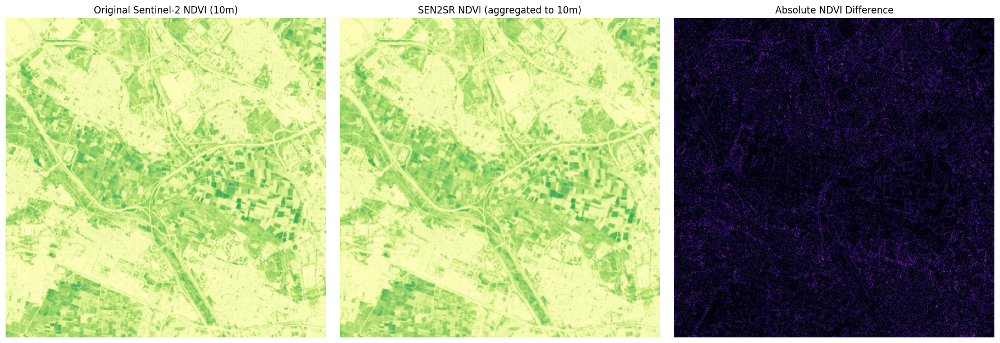

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(ndvi_original, cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_title("Original Sentinel-2 NDVI (10m)")
axes[0].axis("off")

axes[1].imshow(ndvi_sr_10m, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("SEN2SR NDVI (aggregated to 10m)")
axes[1].axis("off")

ndvi_difference = np.abs(
    ndvi_original - ndvi_sr_10m
)

axes[2].imshow(ndvi_difference, cmap="magma")
axes[2].set_title("Absolute NDVI Difference")
axes[2].axis("off")

plt.tight_layout()
plt.show()

Check whether the SEN2NEON/OpenSR utilities are available

In [ ]:
import importlib.util

packages = [
    "opensr_utils",
    "sen2sr"
]

for package in packages:
    print(
        package,
        "→",
        "AVAILABLE" if importlib.util.find_spec(package)
        else "NOT INSTALLED"
    )

opensr_utils → NOT INSTALLED
sen2sr → AVAILABLE


In [ ]:
import sen2sr

print("SEN2SR package location:")
print(sen2sr.__file__)

SEN2SR package location:
/usr/local/lib/python3.13/dist-packages/sen2sr/__init__.py
